# Classification Track - Review 2 Part B

**Problem:** Predict whether a room is occupied (`Occupancy` = 0 or 1) from environmental sensors.

**Dataset:** UCI Occupancy Detection. This notebook continues `notebooks/classification.ipynb` (Review 1 Part A) and compares all ten classification algorithms on one newly created, reproducible, stratified 80:20 train/test split.

**Important evaluation note:** The three supplied data files are pooled before splitting. Therefore, the scores from this notebook will not be directly comparable with the old Review 1 scores that used the files' original official split. Because observations are time-dependent, a random row-level split can also produce optimistic results when nearby readings appear in both train and test sets.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

sns.set_theme(palette="colorblind")
RANDOM_STATE = 42


## 1. Data preparation and a stratified train/test split

The three provided files (`datatraining.txt`, `datatest.txt`, and `datatest2.txt`) are pooled into one dataset, then the existing CO2 cleaning rule is applied. We create a **stratified 80:20 random train/test split** with `train_test_split(test_size=0.20, stratify=y, random_state=42)`.

This makes the occupancy-class proportions in train and test approximately equal and ensures that every classifier in this notebook uses exactly the same split. Since the three files are pooled first, this is a new experimental split, not the dataset's original official holdout. Consequently, the results are not directly comparable with the old Part A scores.

**Limitation:** The observations are sequential sensor readings. A random row-wise split can place nearby readings from the same occupancy interval into both train and test, making accuracy look higher than performance on a genuinely later time period or a different room. This experiment meets the stratified-split workflow, but the limitation should be acknowledged when interpreting results.

CO2 readings above 2000 are removed as sensor anomalies, using the same cleaning rule as Part A. Features are Temperature, Light, CO2, HumidityRatio, seconds since midnight (NSM), Weekday, and Weekend. Raw Humidity is left out because HumidityRatio is already the temperature-adjusted humidity supplied with the dataset.


Combined cleaned dataset: (20516, 10)
Training set: (16412, 7)
Testing set: (4104, 7)
Train occupied rate: 0.2295
Test occupied rate: 0.2295
Missing feature values: 0


,Split,Rows,Unoccupied count,Occupied count,Unoccupied (%),Occupied (%)
0,Train,16412,12645,3767,77.05,22.95
1,Test,4104,3162,942,77.05,22.95


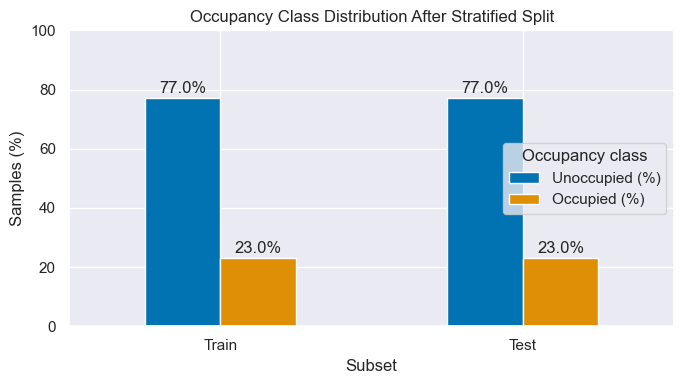

In [2]:
def clean_data(df):
    # Same anomaly rule as Review 1 Part A.
    return df.query("CO2 <= 2000").reset_index(drop=True)


def prepare_features(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["NSM"] = (
        df["date"].dt.hour * 3600
        + df["date"].dt.minute * 60
        + df["date"].dt.second
    )
    # Monday-Friday vs Saturday-Sunday. Weekend is the complement of Weekday.
    df["Weekday"] = df["date"].dt.dayofweek < 5
    df["Weekend"] = df["date"].dt.dayofweek >= 5
    return df


FEATURES = [
    "Temperature",
    "Light",
    "CO2",
    "HumidityRatio",
    "NSM",
    "Weekday",
    "Weekend",
]
TARGET = "Occupancy"

# Pool all supplied files, then apply the same row-cleaning and feature steps.
source_files = [
    "../data/datatraining.txt",
    "../data/datatest.txt",
    "../data/datatest2.txt",
]
raw_data = pd.concat(
    [pd.read_csv(path) for path in source_files],
    ignore_index=True,
)
data = prepare_features(clean_data(raw_data))

X_all = data[FEATURES]
y_all = data[TARGET].astype(int)

# One reproducible, stratified 80:20 split shared by all experiments below.
X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    stratify=y_all,
    random_state=RANDOM_STATE,
)

print("Combined cleaned dataset:", data.shape)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Train occupied rate: {:.4f}".format(y_train.mean()))
print("Test occupied rate: {:.4f}".format(y_test.mean()))
print("Missing feature values:", int(data[FEATURES].isna().sum().sum()))

# Show counts and percentages to verify that stratification worked.
distribution_rows = []
for split_name, labels in [("Train", y_train), ("Test", y_test)]:
    counts = labels.value_counts().reindex([0, 1], fill_value=0)
    distribution_rows.append({
        "Split": split_name,
        "Rows": len(labels),
        "Unoccupied count": int(counts.loc[0]),
        "Occupied count": int(counts.loc[1]),
        "Unoccupied (%)": 100 * counts.loc[0] / len(labels),
        "Occupied (%)": 100 * counts.loc[1] / len(labels),
    })

split_distribution = pd.DataFrame(distribution_rows)
display(split_distribution.round(2))

# Visual check of class proportions in the resulting split.
plot_distribution = split_distribution.set_index("Split")[
    ["Unoccupied (%)", "Occupied (%)"]
]
ax = plot_distribution.plot(
    kind="bar",
    figsize=(7, 4),
    color=sns.color_palette("colorblind", 2),
)
ax.set_title("Occupancy Class Distribution After Stratified Split")
ax.set_xlabel("Subset")
ax.set_ylabel("Samples (%)")
ax.set_ylim(0, 100)
ax.legend(title="Occupancy class")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Split observation

**What to check:** The distribution table and plot above show the class counts and percentages in the new training and test sets. With `stratify=y_all`, the occupied/unoccupied proportions should be nearly identical in both subsets, with small differences possible because of integer row counts. This improves class-balance comparability, but does not eliminate potential leakage from randomly splitting sequential sensor readings.


## 2. Part A models, refit with the Review 1 hyperparameters

These five settings were selected in the Part A grid search (5-fold weighted F1). They are refit here using the **new stratified training split**, so all ten classifiers are evaluated on the same newly generated test split.

Since the split has changed, these results will not reproduce the old Review 1 scores exactly. The Part A hyperparameters are kept fixed for this comparison; the Part B models below are tuned on the new training split.

| Model | Hyperparameters from Part A |
|---|---|
| Logistic Regression | C=10, solver=lbfgs |
| K-Nearest Neighbors | k=19, Manhattan distance |
| Gaussian Naive Bayes | var_smoothing=1e-4 |
| Decision Tree | criterion=entropy, max_depth=3 |
| Support Vector Machine | C=0.1, kernel=linear |

Scaling matches Part A: RobustScaler inside the pipeline for every model except the decision tree. Each scaler is fit only on its applicable training data.


In [3]:
def positive_scores(model, X):
    # The linear SVM matches Part A and was fit without class probabilities.
    # ROC-AUC accepts those decision scores. Every other model uses P(occupied).
    final = model.named_steps["clf"]
    if isinstance(final, SVC):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def metric_row(name, model, track):
    y_pred = model.predict(X_test)
    return {
        "Track": track,
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, positive_scores(model, X_test)),
    }


part_a_models = {
    "Logistic Regression": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", LogisticRegression(C=10.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=19, metric="manhattan")),
    ]),
    "Naive Bayes (Gaussian)": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", GaussianNB(var_smoothing=1e-4)),
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=RANDOM_STATE)),
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", RobustScaler()),
        ("clf", SVC(C=0.1, kernel="linear", random_state=RANDOM_STATE)),
    ]),
}

for name, model in part_a_models.items():
    model.fit(X_train, y_train)
    row = metric_row(name, model, "A")
    print("{:28s}  Acc {:.4f}  F1 {:.4f}  ROC-AUC {:.4f}".format(
        name, row["Accuracy"], row["F1"], row["ROC-AUC"]
    ))


Logistic Regression           Acc 0.9905  F1 0.9906  ROC-AUC 0.9943
K-Nearest Neighbors           Acc 0.9912  F1 0.9913  ROC-AUC 0.9987
Naive Bayes (Gaussian)        Acc 0.9678  F1 0.9685  ROC-AUC 0.9936
Decision Tree                 Acc 0.9900  F1 0.9901  ROC-AUC 0.9957
Support Vector Machine        Acc 0.9912  F1 0.9913  ROC-AUC 0.9940


### Part A refit observation

**Interpretation guide:** Use the printed results above to compare the five Part A models on the new test split. Do not reuse the numerical scores from the earlier official-file split, because the data assigned to training and testing has changed.


## 3. Part B models

Each Part B model is fit twice on the same training rows: a default baseline, then `GridSearchCV` with 5-fold weighted F1. Test metrics of the baseline and the selected model are reported side by side, because a higher cross-validation score does not always raise the test score.

Tree ensembles are left unscaled, matching the Part A decision tree. The MLP uses `RobustScaler` inside the pipeline.

| Model | What is tuned |
|---|---|
| Random Forest | `n_estimators`, `max_depth` |
| AdaBoost | `n_estimators`, `learning_rate` (decision-stump base) |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth` (sklearn GBM) |
| Bagging | `n_estimators`, tree `max_depth` (decision-tree base) |
| MLP | `hidden_layer_sizes`, `activation` |


In [4]:
def make_rf():
    return Pipeline([
        ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    ])


def make_ada():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
            random_state=RANDOM_STATE,
        )),
    ])


def make_gbm():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ])


def make_bag():
    return Pipeline([
        ("clf", BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ])


def make_mlp():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("clf", MLPClassifier(max_iter=400, early_stopping=True, random_state=RANDOM_STATE)),
    ])


# Random Forest and Bagging stay unscaled, matching the Part A decision tree.
# MLP needs scaling. AdaBoost and Gradient Boosting use the same RobustScaler
# pipeline so their inputs match the scaled Part A models.

builders = {
    "Random Forest": make_rf,
    "AdaBoost": make_ada,
    "Gradient Boosting": make_gbm,
    "Bagging": make_bag,
    "MLP": make_mlp,
}

param_grids = {
    "Random Forest": {
        "clf__n_estimators": [100, 200, 300],
        "clf__max_depth": [None, 12, 20],
    },
    "AdaBoost": {
        "clf__n_estimators": [50, 100, 200],
        "clf__learning_rate": [0.05, 0.1, 0.5, 1.0],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1, 0.2],
        "clf__max_depth": [2, 3],
    },
    "Bagging": {
        "clf__n_estimators": [20, 50, 100],
        "clf__estimator__max_depth": [3, 5, None],
    },
    "MLP": {
        "clf__hidden_layer_sizes": [(32,), (64,), (64, 32), (100, 50)],
        "clf__activation": ["relu", "tanh"],
    },
}

baseline_models = {}
tuned_models = {}
search_results = {}

for name, builder in builders.items():
    print("Fitting", name)
    baseline = builder()
    baseline.fit(X_train, y_train)
    baseline_models[name] = baseline

    search = GridSearchCV(
        estimator=builder(),
        param_grid=param_grids[name],
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    search_results[name] = search
    print("  best params:", search.best_params_)
    print("  best CV weighted F1: {:.4f}".format(search.best_score_))


Fitting Random Forest
  best params: {'clf__max_depth': None, 'clf__n_estimators': 100}
  best CV weighted F1: 0.9941
Fitting AdaBoost
  best params: {'clf__learning_rate': 1.0, 'clf__n_estimators': 200}
  best CV weighted F1: 0.9898
Fitting Gradient Boosting
  best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200}
  best CV weighted F1: 0.9925
Fitting Bagging
  best params: {'clf__estimator__max_depth': None, 'clf__n_estimators': 50}
  best CV weighted F1: 0.9938
Fitting MLP
  best params: {'clf__activation': 'tanh', 'clf__hidden_layer_sizes': (32,)}
  best CV weighted F1: 0.9900


## 4. Did tuning change the test score?

`GridSearchCV` selects hyperparameters using the highest mean weighted F1 across training folds. The table below compares each Part B model's baseline and tuned performance on the new held-out test split. The consolidated ten-model table uses each selected (tuned) Part B model.


In [5]:
tuning_rows = []
for name in builders:
    base_row = metric_row(name + " (baseline)", baseline_models[name], "B")
    tuned_row = metric_row(name + " (GridSearch)", tuned_models[name], "B")
    tuning_rows.append({
        "Model": name,
        "Baseline F1": base_row["F1"],
        "Tuned F1": tuned_row["F1"],
        "F1 change": tuned_row["F1"] - base_row["F1"],
        "Baseline ROC-AUC": base_row["ROC-AUC"],
        "Tuned ROC-AUC": tuned_row["ROC-AUC"],
        "ROC-AUC change": tuned_row["ROC-AUC"] - base_row["ROC-AUC"],
        "CV weighted F1": search_results[name].best_score_,
        "Best params": str(search_results[name].best_params_),
    })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df


,Model,Baseline F1,Tuned F1,F1 change,Baseline ROC-AUC,Tuned ROC-AUC,ROC-AUC change,CV weighted F1,Best params
0,Random Forest,0.994161,0.994161,0.000000,0.999455,0.999455,0.000000,0.994097,"{'clf__max_depth': None, 'clf__n_estimators': ..."
1,AdaBoost,0.989822,0.990307,0.000485,0.997706,0.998466,0.000760,0.989761,"{'clf__learning_rate': 1.0, 'clf__n_estimators..."
2,Gradient Boosting,0.991752,0.992470,0.000718,0.998942,0.998960,0.000017,0.992464,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."
3,Bagging,0.993912,0.994163,0.000251,0.998628,0.999425,0.000798,0.993795,"{'clf__estimator__max_depth': None, 'clf__n_es..."
4,MLP,0.990554,0.991045,0.000491,0.994778,0.994189,-0.000590,0.989953,"{'clf__activation': 'tanh', 'clf__hidden_layer..."


### Tuning observation

**Interpretation guide:** Use the table above to identify which searches improved or reduced test weighted F1 and compare those changes with each model's cross-validation score. A stronger training-fold score does not guarantee a stronger held-out test score. Since the data split has changed, any previously recorded numerical observations are no longer valid for this run.


## 5. Confusion matrices

Rows are the true label, columns are the prediction. Labels are Unoccupied (0) and Occupied (1). Part A and the tuned Part B models are shown together.


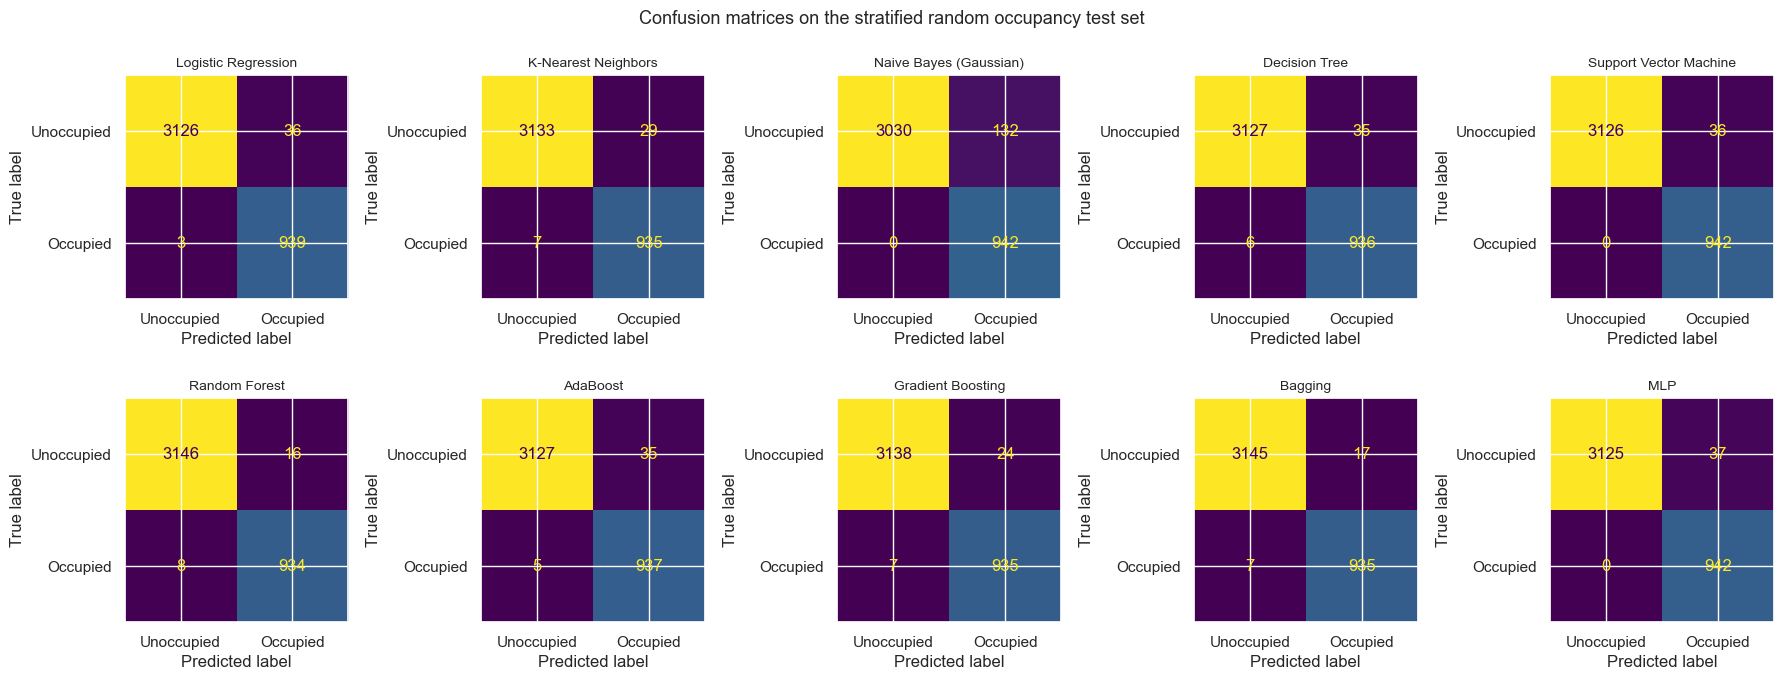

In [6]:
all_models = {}
all_models.update(part_a_models)
all_models.update(tuned_models)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, (name, model) in zip(axes.ravel(), all_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Unoccupied", "Occupied"]).plot(
        ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=10)
fig.suptitle("Confusion matrices on the stratified random occupancy test set", fontsize=13)
fig.tight_layout()
plt.show()


## 6. ROC curves

For the linear SVM, the curve uses decision scores, because that model was fit without class probabilities (same setting as Part A). Every other model uses the predicted probability of the occupied class.


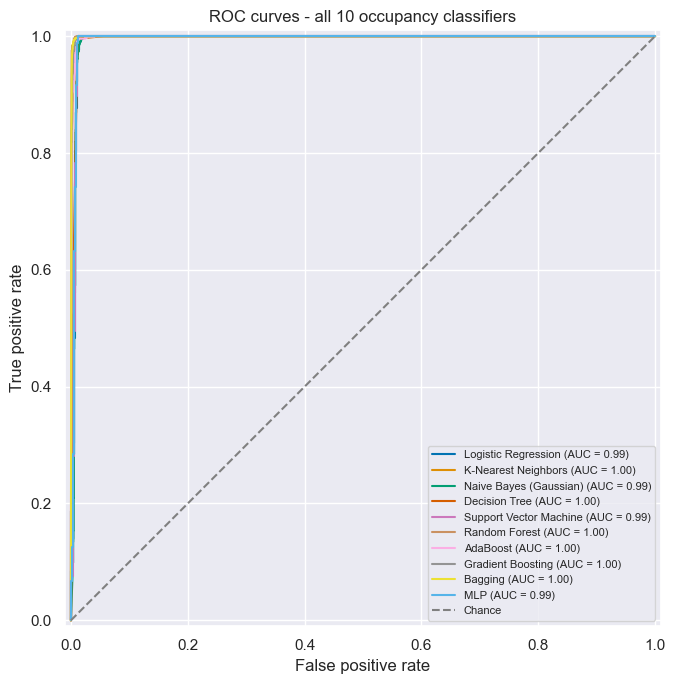

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))
for name, model in all_models.items():
    RocCurveDisplay.from_predictions(
        y_test,
        positive_scores(model, X_test),
        name=name,
        ax=ax,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("ROC curves - all 10 occupancy classifiers")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()


## 7. Random Forest feature importance

Importances are from the tuned forest. They describe how often a feature reduced impurity. They are not causal effects, and Light can dominate because lights are switched with occupancy.


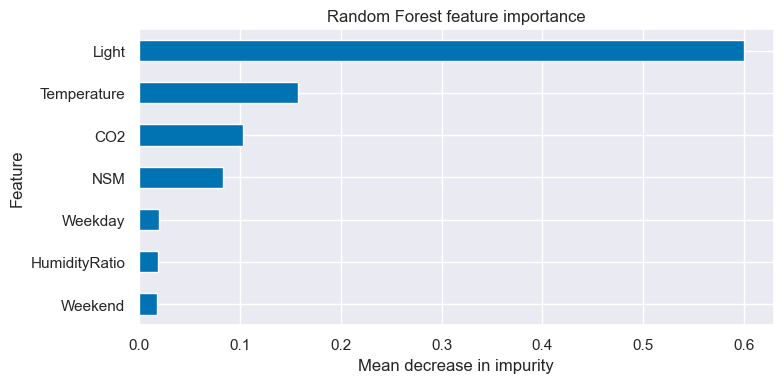

Light            0.5995
Temperature      0.1574
CO2              0.1030
NSM              0.0832
Weekday          0.0196
HumidityRatio    0.0194
Weekend          0.0179
dtype: float64

In [8]:
rf_clf = tuned_models["Random Forest"].named_steps["clf"]
importance = (
    pd.Series(rf_clf.feature_importances_, index=FEATURES)
    .sort_values(ascending=True)
)
fig, ax = plt.subplots(figsize=(8, 4))
importance.plot.barh(ax=ax, color="C0")
ax.set_title("Random Forest feature importance")
ax.set_xlabel("Mean decrease in impurity")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(4)


### Feature-importance observation

**Interpretation guide:** Use the displayed Random Forest importance table to identify which features the fitted forest relied on most in this run. These importances describe reductions in tree impurity, not causal effects. Weekday and Weekend are complementary calendar indicators, so their individual importances should be interpreted together.


## 8. All ten classifiers

One test-set table. Part B rows are the GridSearch models. Sorted by weighted F1, then ROC-AUC.


In [9]:
rows = []
for name, model in part_a_models.items():
    rows.append(metric_row(name, model, "A"))
for name, model in tuned_models.items():
    rows.append(metric_row(name, model, "B"))

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(["F1", "ROC-AUC", "Accuracy"], ascending=False)
    .reset_index(drop=True)
)
comparison_df.insert(0, "Rank", comparison_df.index + 1)
comparison_df_display = comparison_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    comparison_df_display[col] = comparison_df_display[col].map(lambda v: round(v, 4))
comparison_df_display


,Rank,Track,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,B,Bagging,0.9942,0.9942,0.9942,0.9942,0.9994
1,2,B,Random Forest,0.9942,0.9942,0.9942,0.9942,0.9995
2,3,B,Gradient Boosting,0.9924,0.9925,0.9924,0.9925,0.9990
3,4,A,Support Vector Machine,0.9912,0.9916,0.9912,0.9913,0.9940
4,5,A,K-Nearest Neighbors,0.9912,0.9914,0.9912,0.9913,0.9987
5,6,B,MLP,0.9910,0.9913,0.9910,0.9910,0.9942
6,7,A,Logistic Regression,0.9905,0.9908,0.9905,0.9906,0.9943
7,8,B,AdaBoost,0.9903,0.9905,0.9903,0.9903,0.9985
8,9,A,Decision Tree,0.9900,0.9903,0.9900,0.9901,0.9957
9,10,A,Naive Bayes (Gaussian),0.9678,0.9718,0.9678,0.9685,0.9936


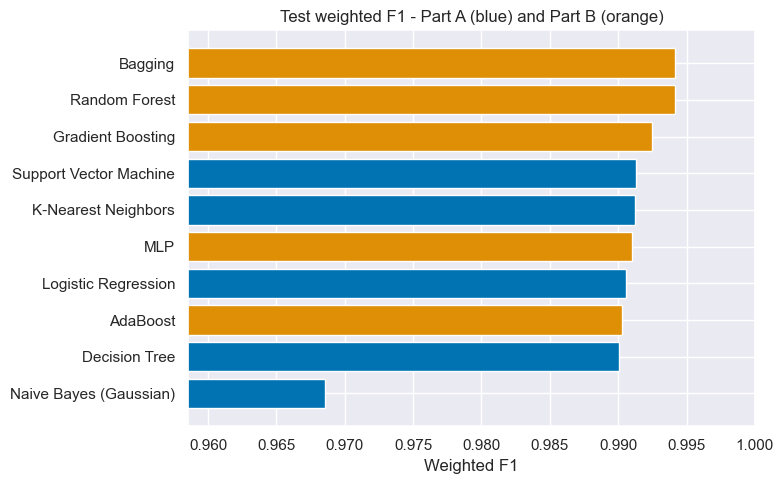

In [10]:
plot_df = comparison_df.sort_values("F1", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["C0" if track == "A" else "C1" for track in plot_df["Track"]]
ax.barh(plot_df["Model"], plot_df["F1"], color=colors)
ax.set_xlim(max(0.90, plot_df["F1"].min() - 0.01), 1.0)
ax.set_xlabel("Weighted F1")
ax.set_title("Test weighted F1 - Part A (blue) and Part B (orange)")
fig.tight_layout()
plt.show()


### Comparison observation (all 10)

**Interpretation guide:** Use the consolidated table above to report the ranking by test weighted F1 and discuss whether precision, recall, and ROC-AUC tell a similar story. The ordering and numerical scores may differ from the prior notebook run because all three data files are now pooled before a new stratified split.


## 9. Cross-validation of the two best models

Five-fold weighted F1 on the new training subset (`X_train`, `y_train`). The two models are selected from the ten-model test comparison, then cross-validation is run using training data only. This is a complementary check; the test data are not used to fit the cross-validation folds.


In [11]:
top_two = comparison_df["Model"].head(2).tolist()
cv_rows = []
for name in top_two:
    scores = cross_val_score(
        all_models[name],
        X_train,
        y_train,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
    )
    cv_rows.append({
        "Model": name,
        "CV weighted F1 mean": scores.mean(),
        "CV weighted F1 std": scores.std(),
        "Fold scores": np.round(scores, 4).tolist(),
    })
    print("{:28s}  {:.4f} +/- {:.4f}".format(name, scores.mean(), scores.std()))

cv_df = pd.DataFrame(cv_rows)
cv_df


Bagging                       0.9938 +/- 0.0003
Random Forest                 0.9941 +/- 0.0004


,Model,CV weighted F1 mean,CV weighted F1 std,Fold scores
0,Bagging,0.993795,0.000311,"[0.9939, 0.9939, 0.9936, 0.9942, 0.9933]"
1,Random Forest,0.994097,0.000413,"[0.9939, 0.9948, 0.9942, 0.9939, 0.9936]"


### Cross-validation observation

**Interpretation guide:** Compare the mean and standard deviation of the five-fold weighted F1 scores for the two models printed above. Consider both the cross-validation results and the held-out test metrics; small differences do not necessarily imply a meaningful performance advantage.


In [12]:
best_name = comparison_df.iloc[0]["Model"]
best_model = all_models[best_name]
print("Best model on test weighted F1:", best_name)
print(classification_report(
    y_test,
    best_model.predict(X_test),
    target_names=["Unoccupied", "Occupied"],
    digits=4,
))


Best model on test weighted F1: Bagging
              precision    recall  f1-score   support

  Unoccupied     0.9978    0.9946    0.9962      3162
    Occupied     0.9821    0.9926    0.9873       942

    accuracy                         0.9942      4104
   macro avg     0.9900    0.9936    0.9918      4104
weighted avg     0.9942    0.9942    0.9942      4104



### Selected model

**Interpretation guide:** The code above identifies the top model by weighted F1 on the new test split and prints its classification report. Use the report to discuss precision and recall for both occupancy classes. Compare the selected model with the runner-up and its training-only cross-validation result, without reusing scores from the previous official-file split.


## 10. Dimensionality reduction: PCA and LDA pipelines

This is an **additional experiment** alongside the ten required classifiers above. It compares Logistic Regression with all seven original features against Logistic Regression after dimensionality reduction using **PCA** or **LDA**.

- **PCA** is unsupervised: it finds directions that preserve feature variance without using `Occupancy` labels.
- **LDA** is supervised: as a transformer here, it uses the training labels to find a direction that separates the occupancy classes. Since this is a binary problem, LDA can produce at most one discriminant component.
- Each scaler and dimensionality-reduction step lives inside its `Pipeline`. During five-fold cross-validation, those steps are fitted only on each fold's training portion, preventing preprocessing leakage into that fold's validation data.

Grid search uses **weighted F1** on `X_train` / `y_train`, which come from the pooled dataset and the new stratified split. The new stratified random test subset is used only to report the final comparison after tuning. These experiments do not replace the required ten-model comparison table.

In [13]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Keep the preprocessing consistent with the existing Logistic Regression model.
# The complete Pipeline is refitted independently inside each CV fold.
logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

pca_logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("pca", PCA()),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

lda_logistic_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=1)),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

# With seven input features, PCA components 1-6 actually reduce dimensionality.
pca_component_options = list(range(1, X_train.shape[1]))

pipeline_experiments = {
    "Logistic Regression (all features)": (
        logistic_pipeline,
        {"clf__C": [0.1, 1.0, 10.0]},
    ),
    "PCA + Logistic Regression": (
        pca_logistic_pipeline,
        {
            "pca__n_components": pca_component_options,
            "clf__C": [0.1, 1.0, 10.0],
        },
    ),
    "LDA + Logistic Regression": (
        lda_logistic_pipeline,
        {"clf__C": [0.1, 1.0, 10.0]},
    ),
}

pca_lda_searches = {}
pca_lda_rows = []

for experiment_name, (pipeline, param_grid) in pipeline_experiments.items():
    print("Tuning:", experiment_name)
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    pca_lda_searches[experiment_name] = search

    best_pipeline = search.best_estimator_
    y_pred = best_pipeline.predict(X_test)
    y_prob = best_pipeline.predict_proba(X_test)[:, 1]

    if "pca" in best_pipeline.named_steps:
        reduced_features = best_pipeline.named_steps["pca"].n_components_
    elif "lda" in best_pipeline.named_steps:
        reduced_features = best_pipeline.named_steps["lda"].n_components
    else:
        reduced_features = X_train.shape[1]

    pca_lda_rows.append({
        "Experiment": experiment_name,
        "Original Features": X_train.shape[1],
        "Features After Reduction": reduced_features,
        "Best CV Weighted F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision (weighted)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test Recall (weighted)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test F1 (weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Best Parameters": search.best_params_,
    })

pca_lda_comparison = pd.DataFrame(pca_lda_rows).sort_values(
    "Test F1 (weighted)", ascending=False
).reset_index(drop=True)

# Rounded display table; the underlying DataFrame retains full numeric precision.
pca_lda_display = pca_lda_comparison.copy()
metric_columns = [
    "Best CV Weighted F1",
    "Test Accuracy",
    "Test Precision (weighted)",
    "Test Recall (weighted)",
    "Test F1 (weighted)",
    "Test ROC-AUC",
]
pca_lda_display[metric_columns] = pca_lda_display[metric_columns].round(4)
pca_lda_display

Tuning: Logistic Regression (all features)
Tuning: PCA + Logistic Regression
Tuning: LDA + Logistic Regression


,Experiment,Original Features,Features After Reduction,Best CV Weighted F1,Test Accuracy,Test Precision (weighted),Test Recall (weighted),Test F1 (weighted),Test ROC-AUC,Best Parameters
0,Logistic Regression (all features),7,7,0.9899,0.9905,0.9908,0.9905,0.9906,0.9943,{'clf__C': 10.0}
1,PCA + Logistic Regression,7,6,0.9899,0.9905,0.9908,0.9905,0.9906,0.9943,"{'clf__C': 10.0, 'pca__n_components': 6}"
2,LDA + Logistic Regression,7,1,0.9894,0.9903,0.9906,0.9903,0.9903,0.9939,{'clf__C': 0.1}


### Reading the PCA/LDA results

Use the table above to state which pipeline performs best on the held-out test set, and compare that result with its **training-only cross-validation score**. Do not claim PCA or LDA improves performance unless the measured results support that conclusion. A small test-score difference may not represent a meaningful improvement.

For PCA, the next cell shows the explained-variance ratio of the selected components. This helps describe how much of the feature variance the selected projection retains; it does **not** directly measure how well occupancy classes are separated.

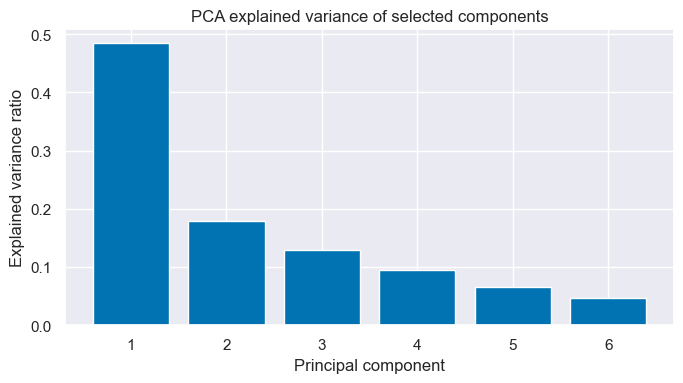

Selected PCA parameters: {'clf__C': 10.0, 'pca__n_components': 6}
Selected PCA components: 6
Total explained variance retained: 1.0000
Selected LDA parameters: {'clf__C': 0.1}


In [14]:
# Inspect the fitted PCA chosen by GridSearchCV.
selected_pca_search = pca_lda_searches["PCA + Logistic Regression"]
selected_pca = selected_pca_search.best_estimator_.named_steps["pca"]
explained_variance = selected_pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 4))
components = np.arange(1, len(explained_variance) + 1)
ax.bar(components, explained_variance)
ax.set_title("PCA explained variance of selected components")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components)
fig.tight_layout()
plt.show()

print("Selected PCA parameters:", selected_pca_search.best_params_)
print("Selected PCA components:", selected_pca.n_components_)
print("Total explained variance retained: {:.4f}".format(explained_variance.sum()))
print("Selected LDA parameters:", pca_lda_searches["LDA + Logistic Regression"].best_params_)